# Import libraries

In [1]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower

In [2]:
chrom = 21

In [3]:
list_of_indexes = []
for element in os.listdir(f"/mnt/d/data_1KG/genotype/segmented/chrom_{chrom}/"):
    list_of_indexes.append(int(element.split("_")[0]))

In [4]:
list_to_pop = list(set(list_of_indexes))

In [5]:
element_list = []
for element in os.listdir(f"/mnt/d/data_1KG/genotype/segmented/chrom_{chrom}/"):
    if int(element.split("_")[0]) in list_to_pop:
        element_list.append(element)
        list_to_pop.remove(int(element.split("_")[0]))

In [6]:
list_of_snps = []
for file_name in element_list:
    geno = pd.read_pickle(f"/mnt/d/data_1KG/genotype/segmented/chrom_{chrom}/{file_name}")
    list_of_snps.append(geno.T.sample(1).T)

# Run analysis

Whole script to find the best effect to standard deviation ratio to keep 80 power under any allele frequency

In [7]:
start_i = 0
end_i = len(list_of_snps)
humans= pd.read_pickle(f"/mnt/d/data_1KG/phenotype/all.panel")
chrom = 21
dic_of_mafs = {}
snp_num = 0
true_mean = 0
true_effect = 5
iteration = 200
min_power = 0.9
for geno in list_of_snps:
    geno[geno.columns[snp_num]].value_counts()
    num_maj = geno[geno.columns[snp_num]].value_counts()[1]
    num_het = geno[geno.columns[snp_num]].value_counts()[0]
    try:
        num_min = geno[geno.columns[snp_num]].value_counts()[-1]
    except Exception as e:
        num_min = 0
    total_humans = num_maj + num_het + num_min
    maf = (num_min*2 + num_het)/(total_humans*2)
    dic_of_mafs[maf] = {}
    for ratio in list(range(40))[1:]:
        ratio = ratio/2
        true_sd = true_effect*ratio


        estimated_effect_nul = []
        estimated_intercept_nul = []
        SE_nul = []
        p_nul = []
        
        i = 0
        for i in range(iteration):
            mean_min = true_mean
            mean_het = true_mean
            mean_maj = true_mean
            sigma_min = true_sd
            sigma_het = true_sd
            sigma_maj = true_sd
            pheno = []
            for var in list(geno[geno.columns[snp_num]]):
                if var == 1:
                    pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
                elif var == 0:
                    pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
                else:
                    pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
            df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno_null": pheno})

            X = df_pheno[['geno']]
            y = df_pheno[['pheno_null']]
            reg = LinearRegression().fit(X, y)
            estimated_effect_nul.append(reg.coef_[0][0])
            estimated_intercept_nul.append(reg.intercept_[0])

            # Calculating p values and standard error
            N = len(X)
            p = len(X.columns) + 1
            X_with_intercept = np.empty(shape=(N, p), dtype=float)
            X_with_intercept[:, 0] = 1
            X_with_intercept[:, 1:p] = X.values

            params = np.append(reg.intercept_,reg.coef_)
            predictions = reg.predict(X)
            new_y = (y-predictions)**2
            newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
            MSE = (sum(list(new_y['pheno_null'])))/(len(newX)-len(newX.columns))

            var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())


            sd_b = np.sqrt(var_b)
            ts_b = params/ sd_b

            p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

            SE_nul.append(sd_b[1])
            p_nul.append(p_values[1])
        

        estimated_effect_alt = []
        estimated_intercept_alt = []
        SE_alt = []
        p_alt = []

        for i in range(iteration):
            mean_min = true_mean - true_effect
            mean_het = true_mean
            mean_maj = true_mean + true_effect
            sigma_min = true_sd
            sigma_het = true_sd
            sigma_maj = true_sd
            pheno = []
            for var in list(geno[geno.columns[snp_num]]):
                if var == 1:
                    pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
                elif var == 0:
                    pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
                else:
                    pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
            df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno": pheno})

            X = df_pheno[['geno']]
            y = df_pheno[['pheno']]
            reg = LinearRegression().fit(X, y)
            estimated_effect_alt.append(reg.coef_[0][0])
            estimated_intercept_alt.append(reg.intercept_[0])

            # Calculating p values and standard error
            N = len(X)
            p = len(X.columns) + 1
            X_with_intercept = np.empty(shape=(N, p), dtype=float)
            X_with_intercept[:, 0] = 1
            X_with_intercept[:, 1:p] = X.values

            params = np.append(reg.intercept_,reg.coef_)
            predictions = reg.predict(X)
            new_y = (y-predictions)**2
            newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
            MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))

            var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
            sd_b = np.sqrt(var_b)
            ts_b = params/ sd_b

            p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
            SE_alt.append(sd_b[1])
            p_alt.append(p_values[1])
            
        
        dis_only_alt = pd.DataFrame(data={"Z": list(estimated_effect_alt)})
        dis_only_alt['Z2'] = (dis_only_alt['Z']/SE_alt)**2
        cuttof = stats.chi2.ppf(min_power, df=1)
        omega = 0
        for val in list(dis_only_alt['Z2']):
            if val > cuttof:
                omega += 1
            else:
                pass
        power = round(omega/len(list(dis_only_alt['Z2']))*100,8)
        dic_of_mafs[maf][ratio] = power
    start_i += 1
    print(start_i/end_i *100)
pd.DataFrame(data = dic_of_mafs).to_pickle("./df_ratio_vs_power.pkl")

10.0
20.0
30.0
40.0
50.0
60.0
70.0
80.0
90.0
100.0


In [8]:
pd.DataFrame(data = dic_of_mafs).to_pickle("./df_ratio_vs_power.pkl")

# Loading ratios vs power

In [9]:
df_ratios_power = pd.read_pickle("./df_ratio_vs_power.pkl")

In [10]:
df_ratios_power

,0.130990,0.255192,0.155551,0.015775,0.223442,0.322883,0.097444,0.354034,0.442891,0.063698
0.5,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
1.5,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2.5,100.0,100.0,100.0,98.5,100.0,100.0,100.0,100.0,100.0,100.0
3.0,100.0,100.0,100.0,90.0,100.0,100.0,100.0,100.0,100.0,100.0
3.5,100.0,100.0,100.0,81.0,100.0,100.0,100.0,100.0,100.0,99.5
4.0,100.0,100.0,100.0,76.5,100.0,100.0,100.0,100.0,100.0,99.5
4.5,100.0,100.0,100.0,64.0,100.0,100.0,99.5,100.0,100.0,99.5
5.0,100.0,100.0,100.0,55.5,100.0,100.0,98.5,100.0,100.0,98.0


In [11]:
pwr = 80 # We want 80% power

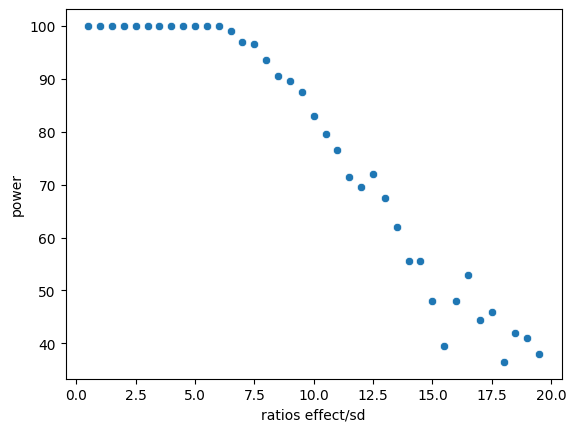

In [12]:
i = 2
df = pd.DataFrame()
df['ratios effect/sd'] = df_ratios_power.index
df['power'] = list(df_ratios_power[df_ratios_power.columns[i]])
sns.scatterplot(data=df, x="ratios effect/sd", y="power")
plt.show()

## Stack all the information into a pandas df

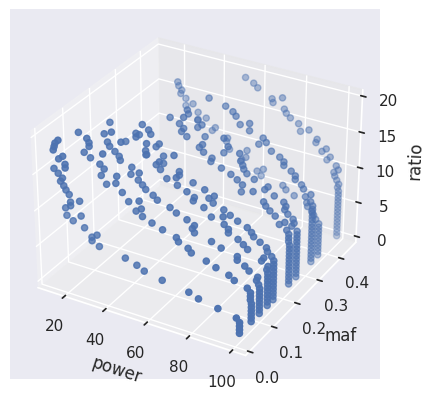

In [13]:
concated = pd.DataFrame()
for col in list(df_ratios_power.columns)[0:1]:
    concated['power'] = df_ratios_power[col]
    concated['maf'] = np.ones(len(df_ratios_power[col])) * float(col)
    concated['ratio'] = df_ratios_power.index
for col in list(df_ratios_power.columns)[1:]:
    temp = pd.DataFrame()
    temp['power'] = df_ratios_power[col]
    temp['maf'] = np.ones(len(df_ratios_power[col])) * float(col)
    temp['ratio'] = df_ratios_power.index
    concated = pd.concat([concated, temp])
    
    from mpl_toolkits.mplot3d import Axes3D

sns.set(style = "darkgrid")

fig = plt.figure()
ax = fig.add_subplot(111, projection = '3d')

x = concated['power']
y = concated['maf']
z = concated['ratio']

ax.set_xlabel("power")
ax.set_ylabel("maf")
ax.set_zlabel("ratio")

ax.scatter(x, y, z)
plt.show()

### Keep only the ratios corresponding to the power we want

In [14]:
rslt_df = concated[pwr-2 < concated['power']]
rslt_df = rslt_df[rslt_df['power'] < pwr+2]

### Find the second order function values

In [15]:
rslt_df

,power,maf,ratio
9.0,81.5,0.130990,9.0
9.5,81.5,0.130990,9.5
10.0,79.5,0.130990,10.0
11.0,79.0,0.130990,11.0
12.5,79.5,0.255192,12.5
10.5,79.5,0.155551,10.5
3.5,81.0,0.015775,3.5
14.5,80.0,0.322883,14.5
14.0,81.0,0.442891,14.0
15.0,80.0,0.442891,15.0


In [16]:
rslt_df = rslt_df.sort_values(by=['maf'])

In [17]:
mafs = np.array(rslt_df['maf'])
ratios = np.array(rslt_df['ratio'])
p = np.polyfit(mafs,ratios,2)
p

array([-77.9589112 ,  60.02449114,   3.13051994])

In [18]:
x1 = np.linspace(0, rslt_df.maf.max(), 50)
y1 = p[0]*x1**2+ p[1]*x1 + p[2]

### Find values manually

based on second order approximation and that

when x = min_maf, y = min_ratio

when maf_max, derivative = 0

when maf_max, y = max_ratio

In [19]:
a = (ratios.min()-ratios.max())/(mafs.max())**2
b = -2*a*mafs.max()
c = ratios.min()

In [20]:
y2 = a*x1**2+ b*x1 + c

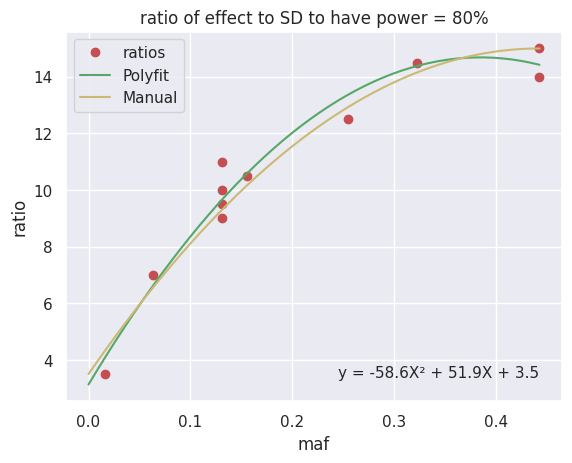

In [21]:
plt.plot(mafs ,ratios,'ro',label='ratios')
plt.plot(x1,y1,color='g',label='Polyfit')
plt.plot(x1,y2,color='y',label='Manual')
plt.legend()
plt.xlabel("maf")
plt.ylabel("ratio")
plt.title(f"ratio of effect to SD to have power = {pwr}%")
plt.text(0.8, 0.1, f"y = {round(a,1)}X\u00b2 + {round(b,1)}X + {round(c,1)}", horizontalalignment='center',
     verticalalignment='center', transform=ax.transAxes, fontsize=11)
plt.show()

In [22]:
def find_power_vals(pwr):
    df_ratios_power = pd.read_pickle("./df_ratio_vs_power.pkl")
    concated = pd.DataFrame()
    for col in list(df_ratios_power.columns)[0:1]:
        concated['power'] = df_ratios_power[col]
        concated['maf'] = np.ones(len(df_ratios_power[col])) * float(col)
        concated['ratio'] = df_ratios_power.index
    for col in list(df_ratios_power.columns)[1:]:
        temp = pd.DataFrame()
        temp['power'] = df_ratios_power[col]
        temp['maf'] = np.ones(len(df_ratios_power[col])) * float(col)
        temp['ratio'] = df_ratios_power.index
        concated = pd.concat([concated, temp])
        rslt_df = concated[pwr-2 < concated['power']]
        rslt_df = rslt_df[rslt_df['power'] < pwr+2]
        
    mafs = np.array(rslt_df['maf'])
    ratios = np.array(rslt_df['ratio'])
    a = (ratios.min()-ratios.max())/(mafs.max())**2
    b = -2*a*mafs.max()
    c = ratios.min()
    return [a, b, c]

In [23]:
find_power_vals(95)

[-33.13743687397398, 29.352569882777274, 6.0]